In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error

from pathlib import Path

/opt/anaconda3/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Importing plotly failed. Interactive plots will not work.


In [ ]:
# Cấu hình đường dẫn theo cây thư mục project/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "weather_clean.csv"
OUTPUT_DIR = PROJECT_ROOT / "results" / "forecast_H2_2026"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [ ]:
# Đọc dữ liệu
df = pd.read_csv(DATA_PATH)

# Kiểm tra các cột
print("Các cột trong dữ liệu:")
print(df.columns.tolist())

# Chỉ chuyển đổi những cột cần thiết cho Prophet
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["tavg"] = pd.to_numeric(df["tavg"], errors="coerce")

# Loại bỏ dòng thiếu ngày hoặc nhiệt độ trung bình
df = df.dropna(subset=["date", "tavg"]).copy()

# Sắp xếp dữ liệu theo ngày
df = df.sort_values("date").reset_index(drop=True)

print("\nSố dòng hợp lệ:", len(df))
print("Ngày đầu tiên:", df["date"].min().date())
print("Ngày cuối cùng:", df["date"].max().date())
print("Số ngày bị trùng:", df["date"].duplicated().sum())

# Hiển thị 5 dòng đầu
display(df.head())

Các cột trong dữ liệu:
['date', 'tavg', 'tmin', 'tmax', 'prcp', 'snow', 'wspd', 'wpgt', 'pres', 'tsun', 'split', 'co_ngoai_lai_tavg']

Số dòng hợp lệ: 2373
Ngày đầu tiên: 2020-01-01
Ngày cuối cùng: 2026-06-30
Số ngày bị trùng: 0


,date,tavg,tmin,tmax,prcp,snow,wspd,wpgt,pres,tsun,split,co_ngoai_lai_tavg
0,2020-01-01,0.4,-3.6,4.5,0.1,0,10.1,22.3,1035.5,438,train,False
1,2020-01-02,-0.5,-2.4,1.4,0.0,0,6.1,25.9,1031.2,0,train,False
2,2020-01-03,5.8,1.3,9.3,0.5,0,15.5,46.8,1024.4,0,train,False
3,2020-01-04,5.4,2.4,6.8,0.2,0,15.8,47.5,1031.5,0,train,False
4,2020-01-05,4.8,2.7,6.3,1.1,0,6.8,23.4,1036.6,0,train,False


In [ ]:
# Mốc thời gian huấn luyện mới
train_end_date = pd.Timestamp("2026-06-30")
train_data = df[df["date"] <= train_end_date].copy()

# Chuẩn bị dữ liệu cho mô hình
train = train_data[["date", "tavg"]].rename(columns={"date": "ds", "tavg": "y"})

print("Số quan sát huấn luyện:", len(train))
print("Huấn luyện từ:", train["ds"].min().date(), "đến", train["ds"].max().date())

Số quan sát huấn luyện: 2373
Huấn luyện từ: 2020-01-01 đến 2026-06-30


In [4]:
# Khởi tạo mô hình với bộ tham số tốt nhất đã tìm ra từ các bước trước
final_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False,
    changepoint_prior_scale=0.01,
    seasonality_prior_scale=5.0,
    seasonality_mode="multiplicative",
    interval_width=0.95
)

# Refit (huấn luyện lại) mô hình với toàn bộ dữ liệu đến 30/06/2026
final_model.fit(train)
print("Đã refit mô hình thành công!")

23:00:03 - cmdstanpy - INFO - Chain [1] start processing
23:00:03 - cmdstanpy - INFO - Chain [1] done processing


Đã refit mô hình thành công!


In [5]:
# Tạo khung thời gian tương lai cho 184 ngày của H2/2026
future_H2_2026 = pd.DataFrame({
    "ds": pd.date_range(
        start="2026-07-01",
        end="2026-12-31",
        freq="D"
    )
})

# Chạy dự báo
forecast = final_model.predict(future_H2_2026)

# Trích xuất các cột kết quả
forecast_result = forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].copy()
forecast_result = forecast_result.rename(columns={
    "ds": "date",
    "yhat": "forecast_tavg",
    "yhat_lower": "lower_95",
    "yhat_upper": "upper_95"
})

In [ ]:
# Lưu kết quả cuối cùng ra file
csv_output_path = OUTPUT_DIR / "Du_bao_H2_2026_Prophet.csv"
forecast_result.to_csv(csv_output_path, index=False, encoding="utf-8-sig")
print("Đã lưu file thành công:", csv_output_path)

Đã lưu file thành công: Du_bao_H2_2026_Prophet.csv


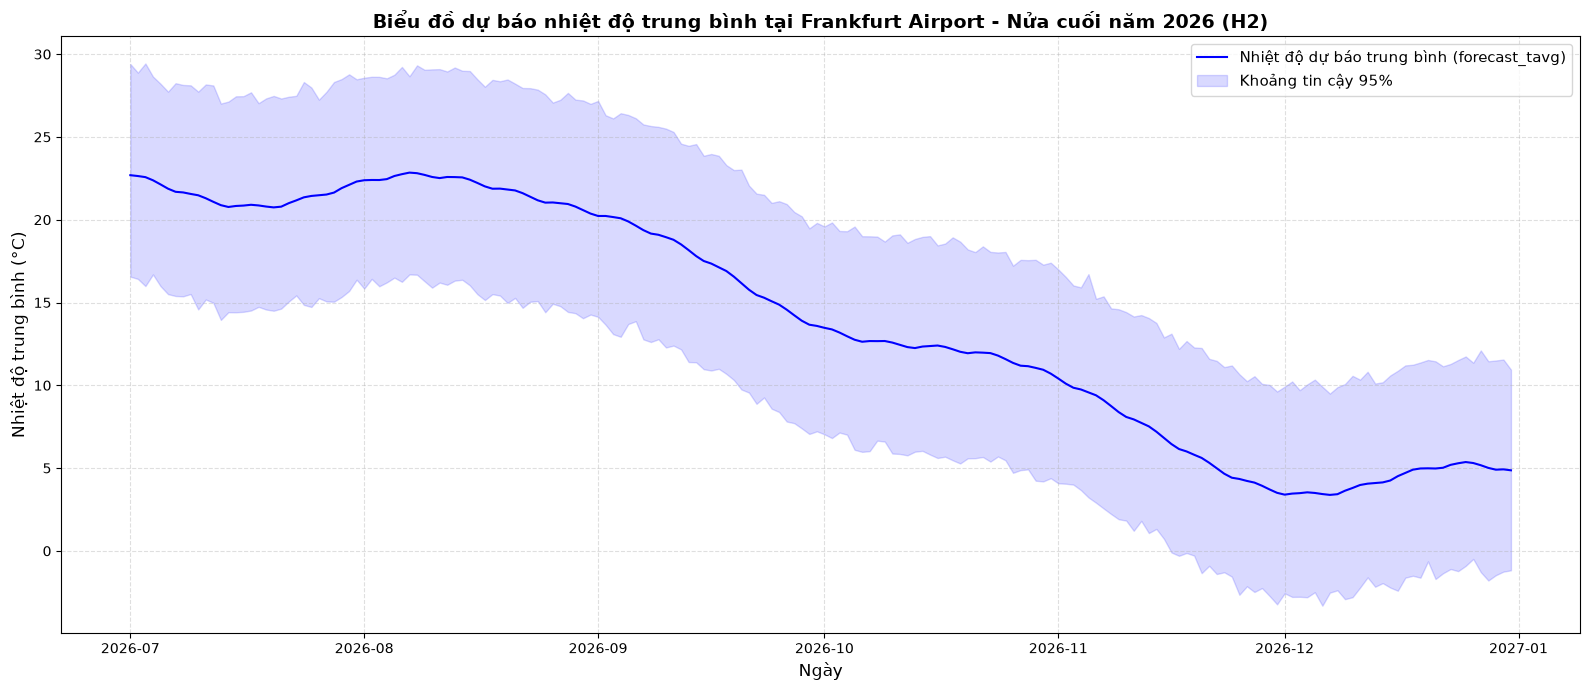

Đã vẽ và lưu biểu đồ thành công: Bieu_do_du_bao_H2_2026.png


In [ ]:
# Vẽ biểu đồ dự báo nhiệt độ H2/2026 (01/07/2026 - 31/12/2026)
plt.figure(figsize=(16, 7))

# Đường dự báo trung tâm (yhat)
plt.plot(
    forecast_result["date"],
    forecast_result["forecast_tavg"],
    color="blue",
    linewidth=1.5,
    label="Nhiệt độ dự báo trung bình (forecast_tavg)"
)

# Vùng khoảng tin cậy 95% (lower_95 đến upper_95)
plt.fill_between(
    forecast_result["date"],
    forecast_result["lower_95"],
    forecast_result["upper_95"],
    color="blue",
    alpha=0.15,
    label="Khoảng tin cậy 95%"
)

plt.title("Biểu đồ dự báo nhiệt độ trung bình tại Frankfurt Airport - Nửa cuối năm 2026 (H2)", fontsize=14, fontweight='bold')
plt.xlabel("Ngày", fontsize=12)
plt.ylabel("Nhiệt độ trung bình (°C)", fontsize=12)
plt.legend(loc="best", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()

# Lưu biểu đồ thành file ảnh để đưa vào báo cáo
plot_output_path = OUTPUT_DIR / "Bieu_do_du_bao_H2_2026.png"
plt.savefig(plot_output_path, dpi=300, bbox_inches="tight")
plt.show()
print("Đã vẽ và lưu biểu đồ thành công:", plot_output_path)